# Assignment: Exploratory Data Analysis (EDA) Using Python
**Course:** Programming for AI  |  **Dataset:** Palmer Penguins  |  **Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, scikit-learn

Student: *(your name / roll no.)*

> Note on the data source: the notebook reads `data/penguins.csv`, the original Palmer Penguins CSV (344 records, 7 columns). Every task below is done in code; nothing was cleaned by hand.

## Task 1 — Load and Understand the Dataset

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
os.makedirs('figures', exist_ok=True)

df = pd.read_csv('data/penguins.csv')
print('First 5 records:');  display(df.head())
print('Last 5 records:');   display(df.tail())

First 5 records:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


Last 5 records:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE
343,Gentoo,Biscoe,49.9,16.1,213.0,5400.0,MALE


In [2]:
print('Rows    :', df.shape[0])
print('Columns :', df.shape[1])
print('\nColumn names:', list(df.columns))
print('\nData types:'); print(df.dtypes)

Rows    : 344
Columns : 7

Column names: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']

Data types:
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
dtype: object


In [3]:
print('Numerical summary:');   display(df.describe())
print('Categorical summary:'); display(df.describe(include='object'))

Numerical summary:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


Categorical summary:


,species,island,sex
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,MALE
freq,152,168,168


**Interpretation.** The dataset has 344 rows (one per penguin) and 7 columns: three categorical (`species`, `island`, `sex`) and four numerical measurements (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Numeric columns have a count of 342 instead of 344, and `sex` has fewer than 344 values, so there are missing values to deal with. The typical penguin weighs about 4.2 kg with a ~201 mm flipper, and there are three species (Adelie is the most common) living on three islands.

## Task 2 — Identify and Handle Missing Values

In [4]:
missing = df.isnull().sum()
report_before = pd.DataFrame({'missing_count': missing,
                              'missing_percent': (missing / len(df) * 100).round(2)})
display(report_before)
print('Total missing cells:', int(missing.sum()), 'out of', df.size,
      f'({missing.sum()/df.size*100:.2f}%)')
print('Rows with at least one missing value:', int(df.isnull().any(axis=1).sum()))

,missing_count,missing_percent
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20


Total missing cells: 19 out of 2408 (0.79%)
Rows with at least one missing value: 11


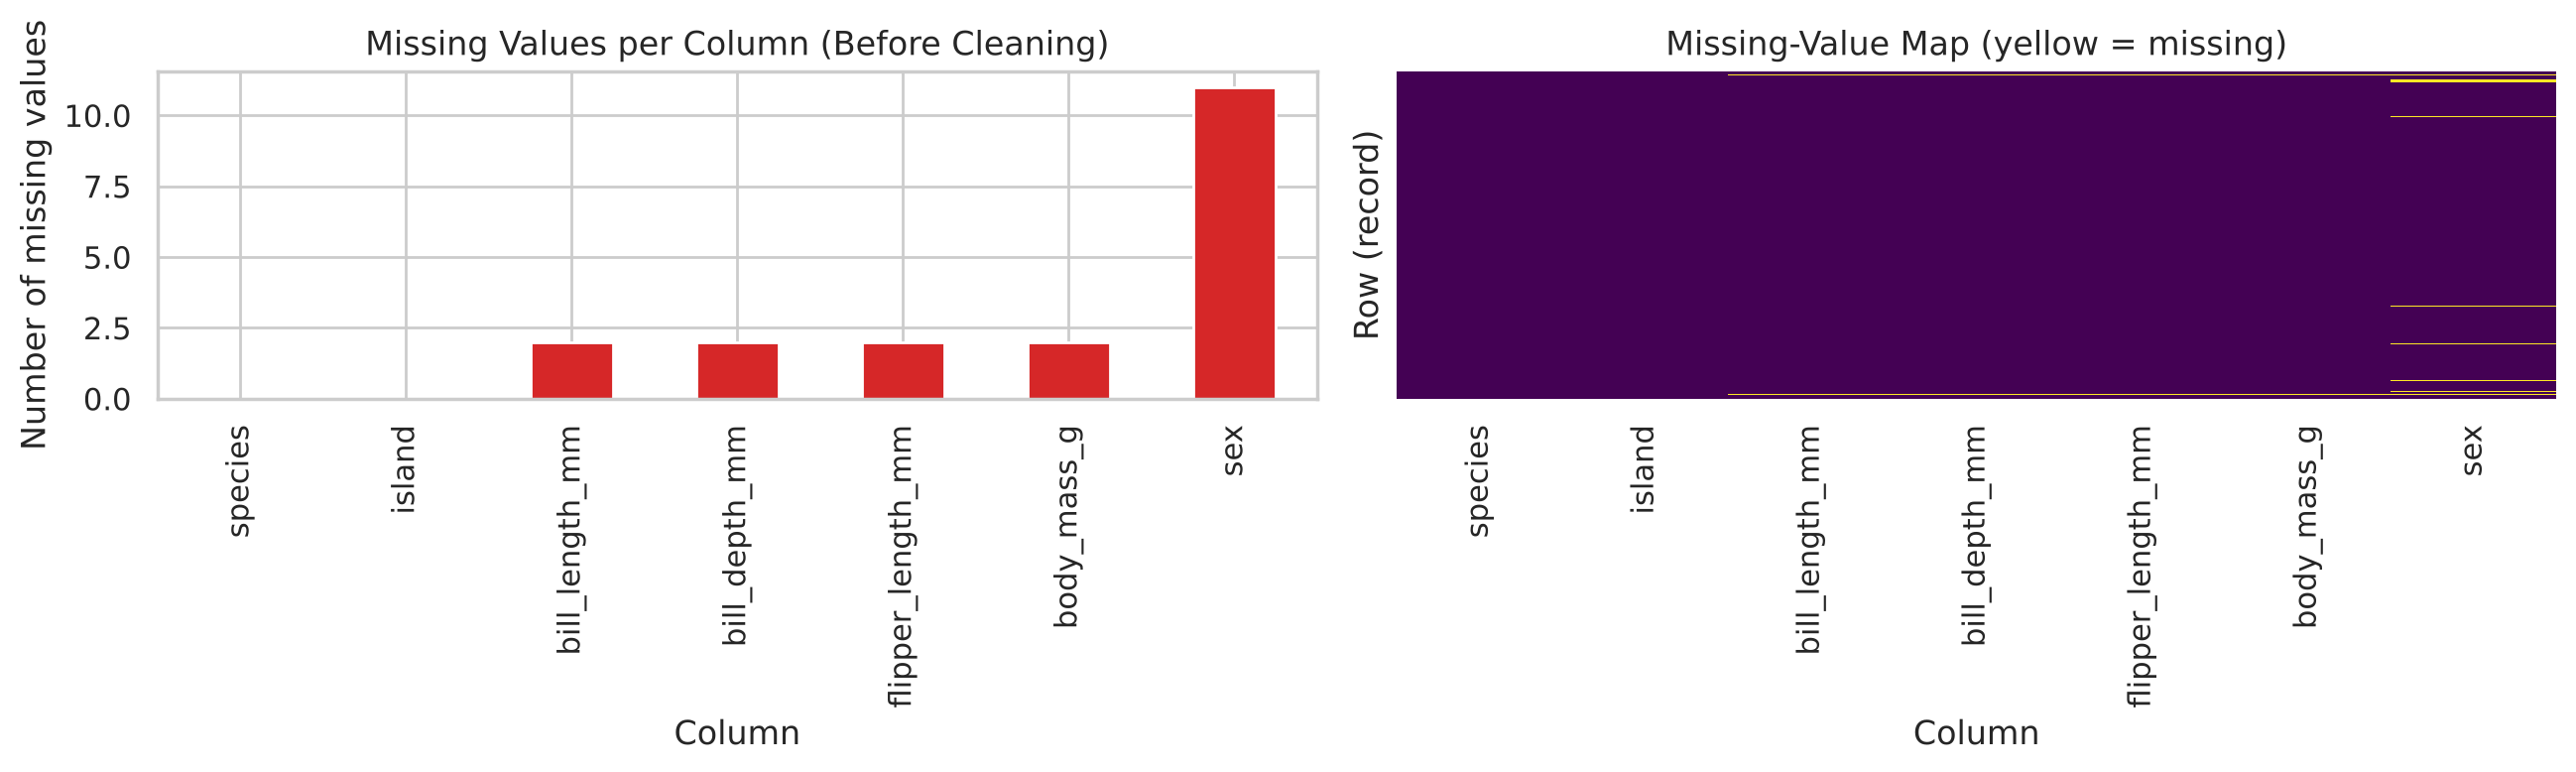

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
missing.plot(kind='bar', ax=ax[0], color='tab:red')
ax[0].set_title('Missing Values per Column (Before Cleaning)')
ax[0].set_xlabel('Column'); ax[0].set_ylabel('Number of missing values')
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, ax=ax[1], cmap='viridis')
ax[1].set_title('Missing-Value Map (yellow = missing)')
ax[1].set_xlabel('Column'); ax[1].set_ylabel('Row (record)')
plt.tight_layout(); plt.savefig('figures/01_missing_values.png', dpi=150); plt.show()

In [6]:
# Check the skew of each numeric column to choose mean vs. median
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
display(pd.DataFrame({'mean': df[num_cols].mean(), 'median': df[num_cols].median(),
                      'skew': df[num_cols].skew()}).round(3))
# Are the missing rows the same ones?
display(df[df[num_cols].isnull().any(axis=1)])

,mean,median,skew
bill_length_mm,43.922,44.45,0.053
bill_depth_mm,17.151,17.30,-0.143
flipper_length_mm,200.915,197.00,0.346
body_mass_g,4201.754,4050.00,0.470


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


In [7]:
df_before_missing = df.copy()          # keep a copy for the before/after comparison

for col in num_cols:                    # numerical -> median
    df[col] = df[col].fillna(df[col].median())

cat_cols = ['species', 'island', 'sex']
for col in cat_cols:                    # categorical -> mode
    df[col] = df[col].fillna(df[col].mode()[0])

report_after = pd.DataFrame({'before': df_before_missing.isnull().sum(), 'after': df.isnull().sum()})
display(report_after)
print('Mode used for sex:', df_before_missing['sex'].mode()[0])
display(pd.DataFrame({'mean_before': df_before_missing[num_cols].mean(),
                      'mean_after': df[num_cols].mean(),
                      'std_before': df_before_missing[num_cols].std(),
                      'std_after': df[num_cols].std()}).round(3))

,before,after
species,0,0
island,0,0
bill_length_mm,2,0
bill_depth_mm,2,0
flipper_length_mm,2,0
body_mass_g,2,0
sex,11,0


Mode used for sex: MALE


,mean_before,mean_after,std_before,std_after
bill_length_mm,43.922,43.925,5.460,5.444
bill_depth_mm,17.151,17.152,1.975,1.969
flipper_length_mm,200.915,200.892,14.062,14.024
body_mass_g,4201.754,4200.872,801.955,799.697


**Explanation.** Only 19 of 2,408 cells are missing (≈0.8%): 2 in each measurement column and 11 in `sex` (3.2%). The 2 measurement gaps come from the same two rows, which carry no measurements and no sex at all (rows 3 and 339). I used the **median** for numerical columns because it is not pulled by extreme values and the columns are somewhat skewed/bimodal (three species of very different size), so it is a safe central value; the table above shows the mean and standard deviation barely change after filling. For the categorical column `sex` I used the **mode** since a mean has no meaning for categories and the mode is the most likely label. *Caveat:* imputing `sex` with the mode assumes those 11 penguins are the majority label; with a ratio this close to 50/50 that is a weak assumption, so dropping them or adding a "Unknown" category would also be defensible. I imputed rather than dropped to keep all 344 rows for the next assignment.

## Task 3 — Identify and Remove Duplicate Records

In [8]:
dups_before = df.duplicated().sum()
print('Duplicate rows BEFORE:', dups_before)
display(df[df.duplicated(keep=False)])
df = df.drop_duplicates().reset_index(drop=True)
print('Duplicate rows AFTER :', df.duplicated().sum())
print('Shape after:', df.shape)

Duplicate rows BEFORE: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex


Duplicate rows AFTER : 0
Shape after: (344, 7)


**Explanation.** There are **no exact duplicate rows**, so nothing was removed (I did not invent any). Penguins measured with the same numbers would be a coincidence, but with four continuous measurements per row, a fully identical row would be suspicious; none exist, so the 344 rows are all distinct observations. `drop_duplicates()` was still run and verified (0 duplicates before and after).

## Task 4 — Handle Inconsistent Categorical Data

In [9]:
cat_cols = df.select_dtypes(include='object').columns.tolist()
print('Categorical columns:', cat_cols)
for c in cat_cols:
    print(f'\n--- {c} ---')
    print(df[c].value_counts())
    print('Unique raw values:', df[c].unique().tolist())
    print('Has leading/trailing spaces:', (df[c] != df[c].str.strip()).any())
    print('Case-insensitive unique count:', df[c].str.strip().str.lower().nunique(),
          '| raw unique count:', df[c].nunique())

Categorical columns: ['species', 'island', 'sex']

--- species ---
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
Unique raw values: ['Adelie', 'Chinstrap', 'Gentoo']
Has leading/trailing spaces: False
Case-insensitive unique count: 3 | raw unique count: 3

--- island ---
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64
Unique raw values: ['Torgersen', 'Biscoe', 'Dream']
Has leading/trailing spaces: False
Case-insensitive unique count: 3 | raw unique count: 3

--- sex ---
sex
MALE      179
FEMALE    165
Name: count, dtype: int64
Unique raw values: ['MALE', 'FEMALE']
Has leading/trailing spaces: False
Case-insensitive unique count: 2 | raw unique count: 2


In [10]:
before = df[['species', 'island', 'sex']].head(5).copy()

for c in cat_cols:
    df[c] = df[c].str.strip().str.title()      # trim spaces + consistent capitalisation

after = df[['species', 'island', 'sex']].head(5)
print('BEFORE:'); display(before)
print('AFTER:');  display(after)
print(df['sex'].value_counts())

BEFORE:


,species,island,sex
0,Adelie,Torgersen,MALE
1,Adelie,Torgersen,FEMALE
2,Adelie,Torgersen,FEMALE
3,Adelie,Torgersen,MALE
4,Adelie,Torgersen,FEMALE


AFTER:


,species,island,sex
0,Adelie,Torgersen,Male
1,Adelie,Torgersen,Female
2,Adelie,Torgersen,Female
3,Adelie,Torgersen,Male
4,Adelie,Torgersen,Female


sex
Male      179
Female    165
Name: count, dtype: int64


**Explanation.** The three categorical columns are `species`, `island` and `sex`. There are no stray spaces and no duplicate spellings of the same category (the number of unique values is the same with or without case folding), so the data is already consistent in content. The one *formatting* inconsistency is that `sex` is written in ALL CAPS (`MALE`/`FEMALE`) while `species` and `island` are Title Case, so I standardised all of them with `strip()` + `title()` so every categorical column follows the same style (`Male`/`Female`).

## Task 5 — Detect and Handle Outliers

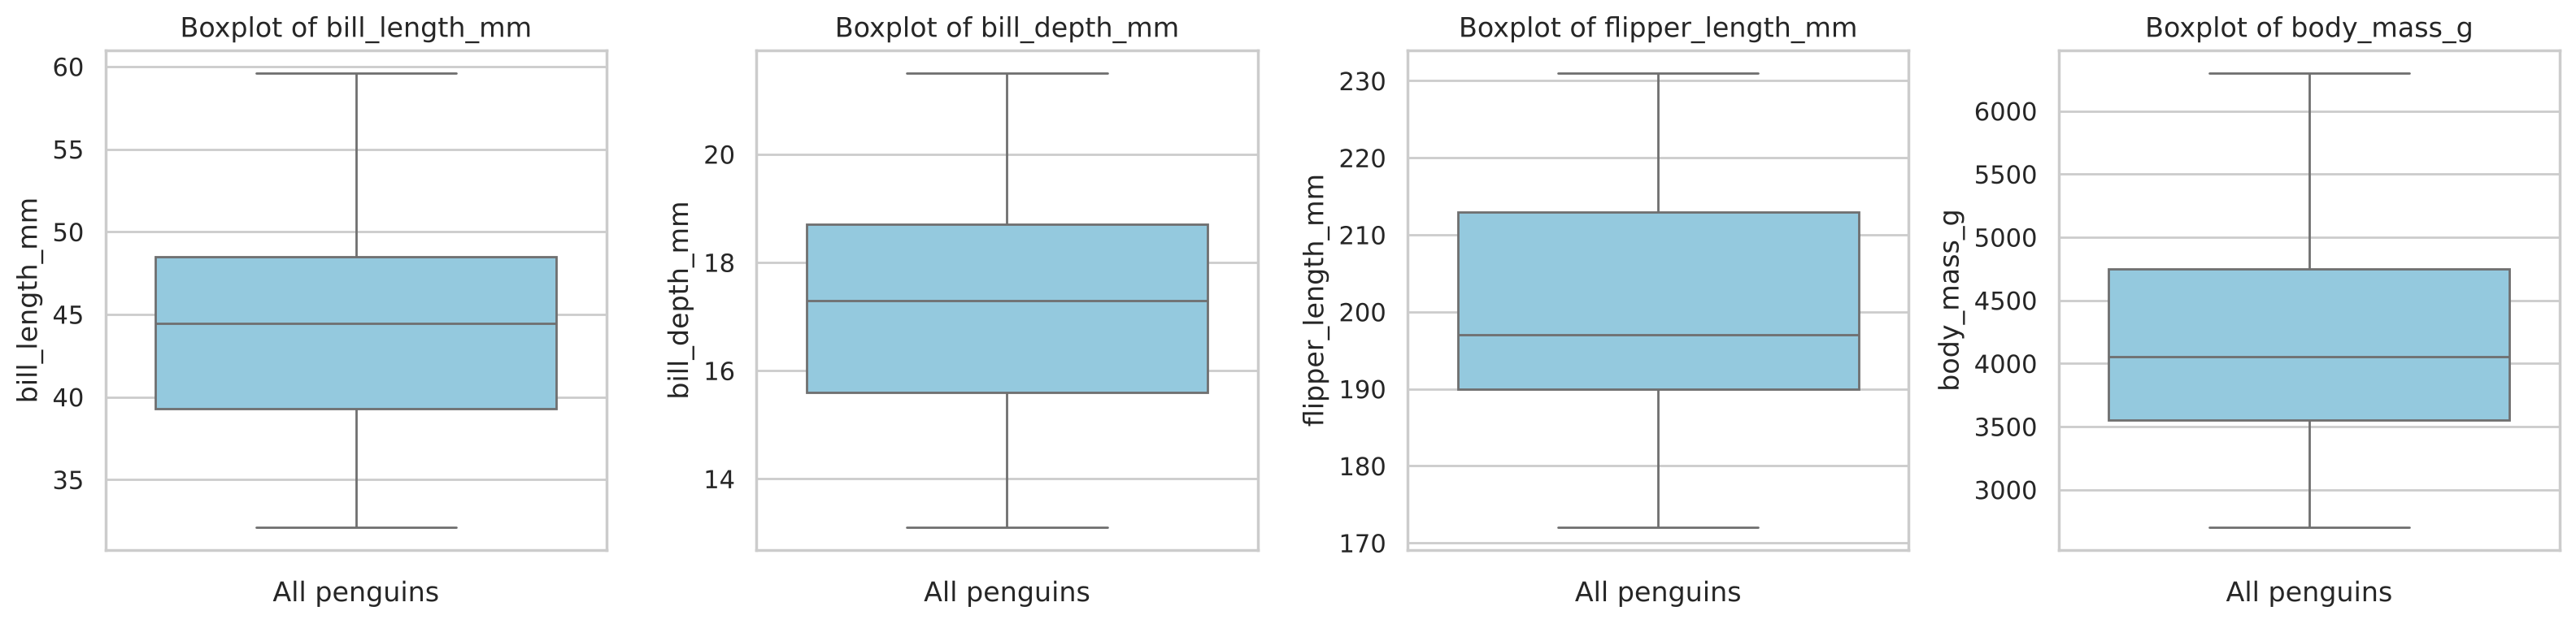

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax, color='skyblue')
    ax.set_title(f'Boxplot of {c}'); ax.set_ylabel(c); ax.set_xlabel('All penguins')
plt.tight_layout(); plt.savefig('figures/02_boxplots_outliers.png', dpi=150); plt.show()

In [12]:
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile(0.25), df[c].quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = df[(df[c] < lo) | (df[c] > hi)]
    rows.append([c, q1, q3, iqr, lo, hi, len(out), df[c].min(), df[c].max()])
iqr_table = pd.DataFrame(rows, columns=['column', 'Q1', 'Q3', 'IQR', 'lower_bound', 'upper_bound',
                                         'n_outliers', 'min', 'max']).set_index('column')
display(iqr_table.round(2))

,Q1,Q3,IQR,lower_bound,upper_bound,n_outliers,min,max
column,,,,,,,,
bill_length_mm,39.28,48.5,9.23,25.44,62.34,0,32.1,59.6
bill_depth_mm,15.60,18.7,3.10,10.95,23.35,0,13.1,21.5
flipper_length_mm,190.00,213.0,23.00,155.50,247.50,0,172.0,231.0
body_mass_g,3550.00,4750.0,1200.00,1750.00,6550.00,0,2700.0,6300.0


,column,species,lower,upper,outlier_values
0,bill_length_mm,Gentoo,38.9,55.9,[59.6]
1,bill_depth_mm,Adelie,15.2,21.3,[21.5]
2,flipper_length_mm,Adelie,172.5,208.5,"[172.0, 210.0]"
3,flipper_length_mm,Gentoo,198.5,234.5,[197.0]
4,body_mass_g,Chinstrap,2793.8,4643.8,"[4800.0, 2700.0]"


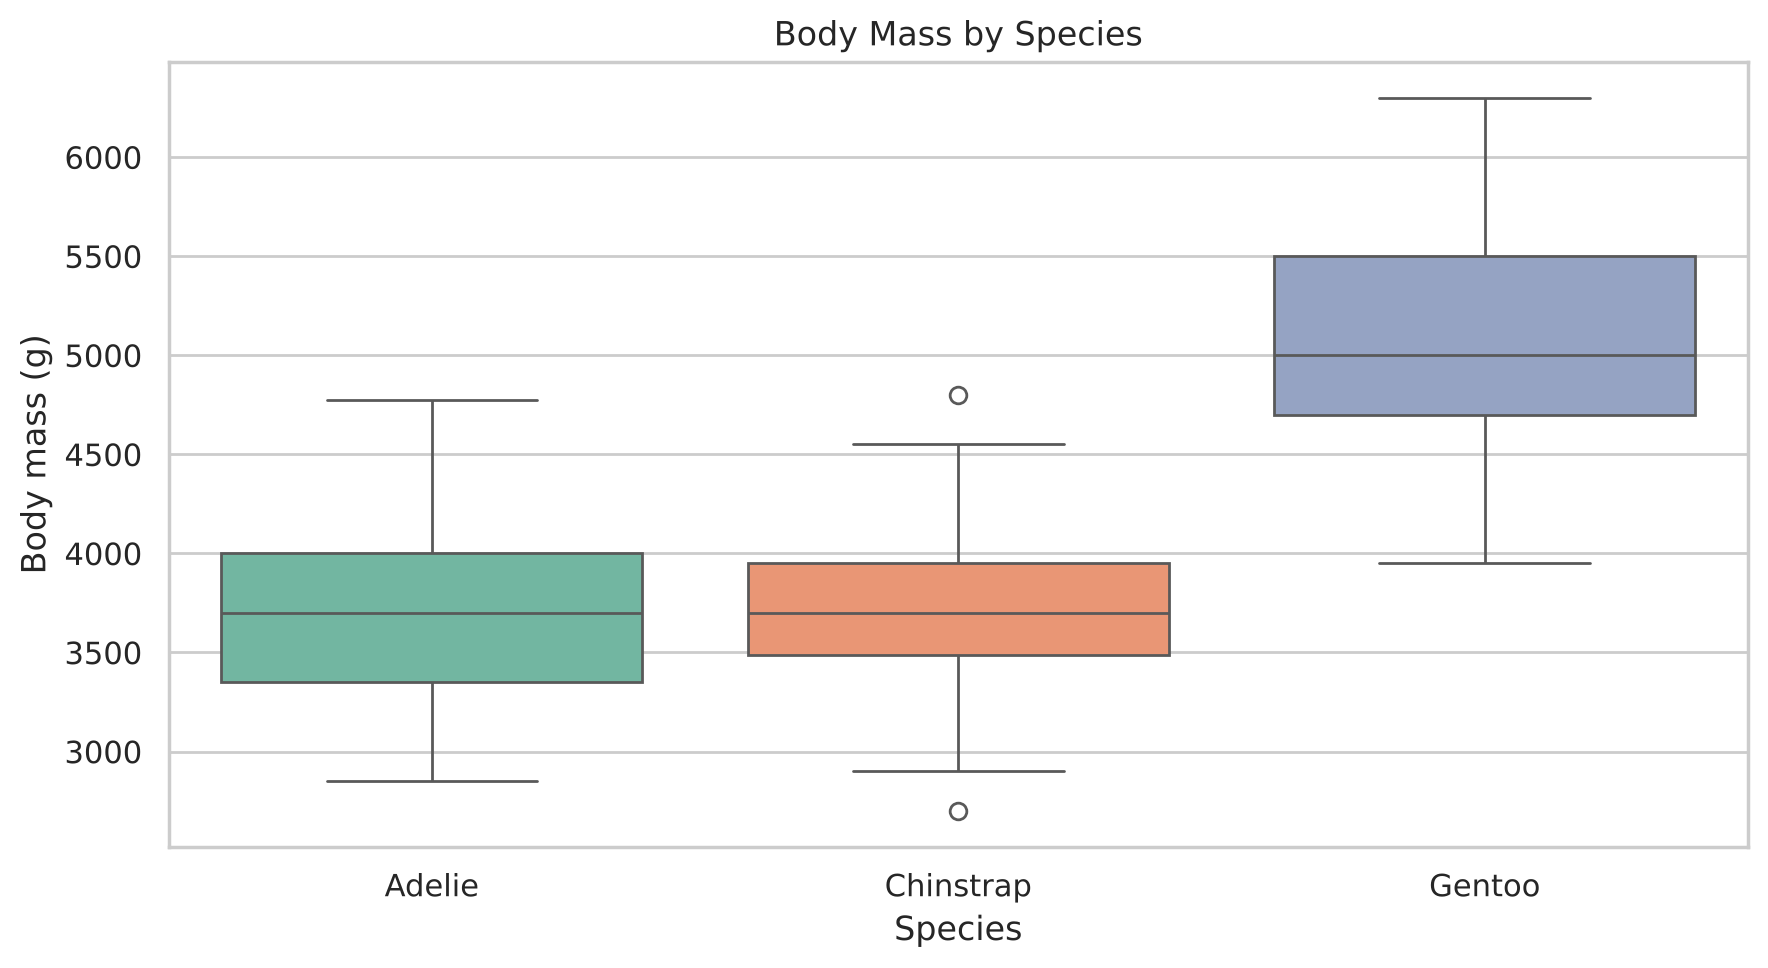

In [13]:
# Investigate more carefully: the three species have very different sizes, so check IQR within each species
rows = []
for c in num_cols:
    for sp, g in df.groupby('species'):
        q1, q3 = g[c].quantile([.25, .75]); iqr = q3 - q1
        lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
        out = g[(g[c] < lo) | (g[c] > hi)]
        if len(out): rows.append([c, sp, round(lo,1), round(hi,1), out[c].tolist()])
display(pd.DataFrame(rows, columns=['column', 'species', 'lower', 'upper', 'outlier_values']))

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='species', y='body_mass_g', palette='Set2')
plt.title('Body Mass by Species'); plt.xlabel('Species'); plt.ylabel('Body mass (g)')
plt.tight_layout(); plt.savefig('figures/03_bodymass_by_species.png', dpi=150); plt.show()

**Decision.** Across the whole dataset **no value falls outside the IQR bounds** for any of the four columns (the `n_outliers` column is 0), and the boxplots agree: the min/max values are all inside the whiskers. I checked each species separately because the species differ a lot in size; any value that looks unusual inside one species (see the second table) is still within a physically plausible range for a penguin (e.g. body mass of a few kg, flipper lengths of 170–230 mm), so it reflects real biological variation, not a typing error. I therefore **retain all values** — no removal or capping — because deleting real variation would remove information and bias the next model. Also, I left the two imputed rows alone since they are now at the median.

## Task 6 — Data Visualization

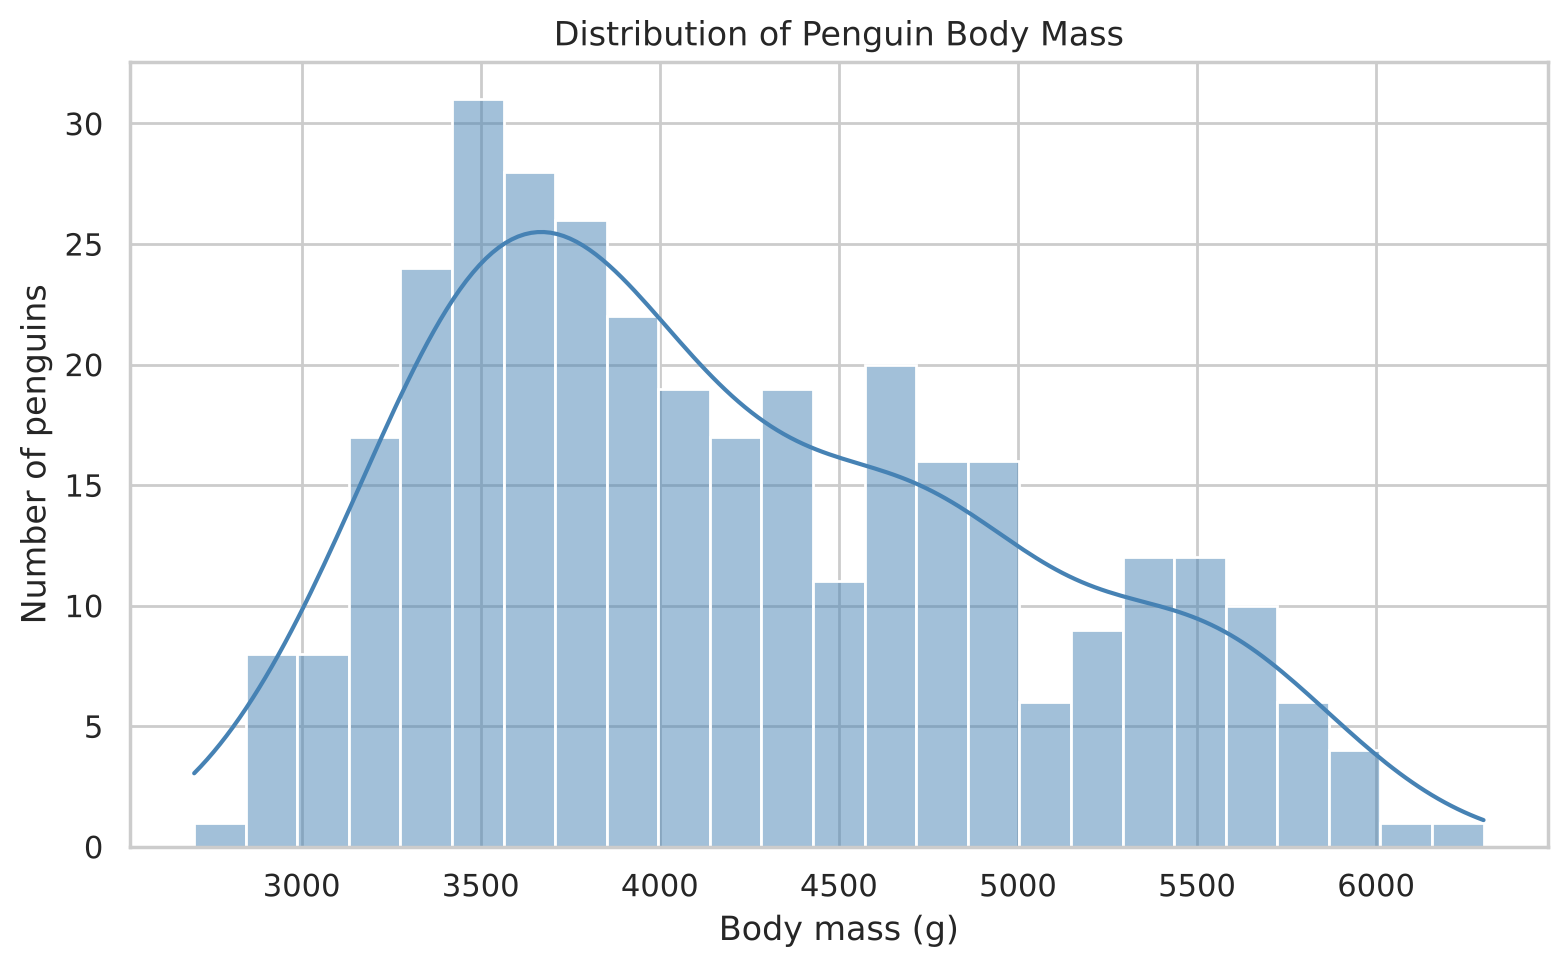

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(df['body_mass_g'], bins=25, kde=True, color='steelblue')
plt.title('Distribution of Penguin Body Mass'); plt.xlabel('Body mass (g)'); plt.ylabel('Number of penguins')
plt.tight_layout(); plt.savefig('figures/04_hist_body_mass.png', dpi=150); plt.show()

**Interpretation.** Body mass is right-skewed and roughly two-humped: most penguins weigh 3,000–4,800 g, with a second group of heavier birds around 5,000–5,500 g (mostly Gentoo), so the data is a mix of subpopulations rather than one bell curve.

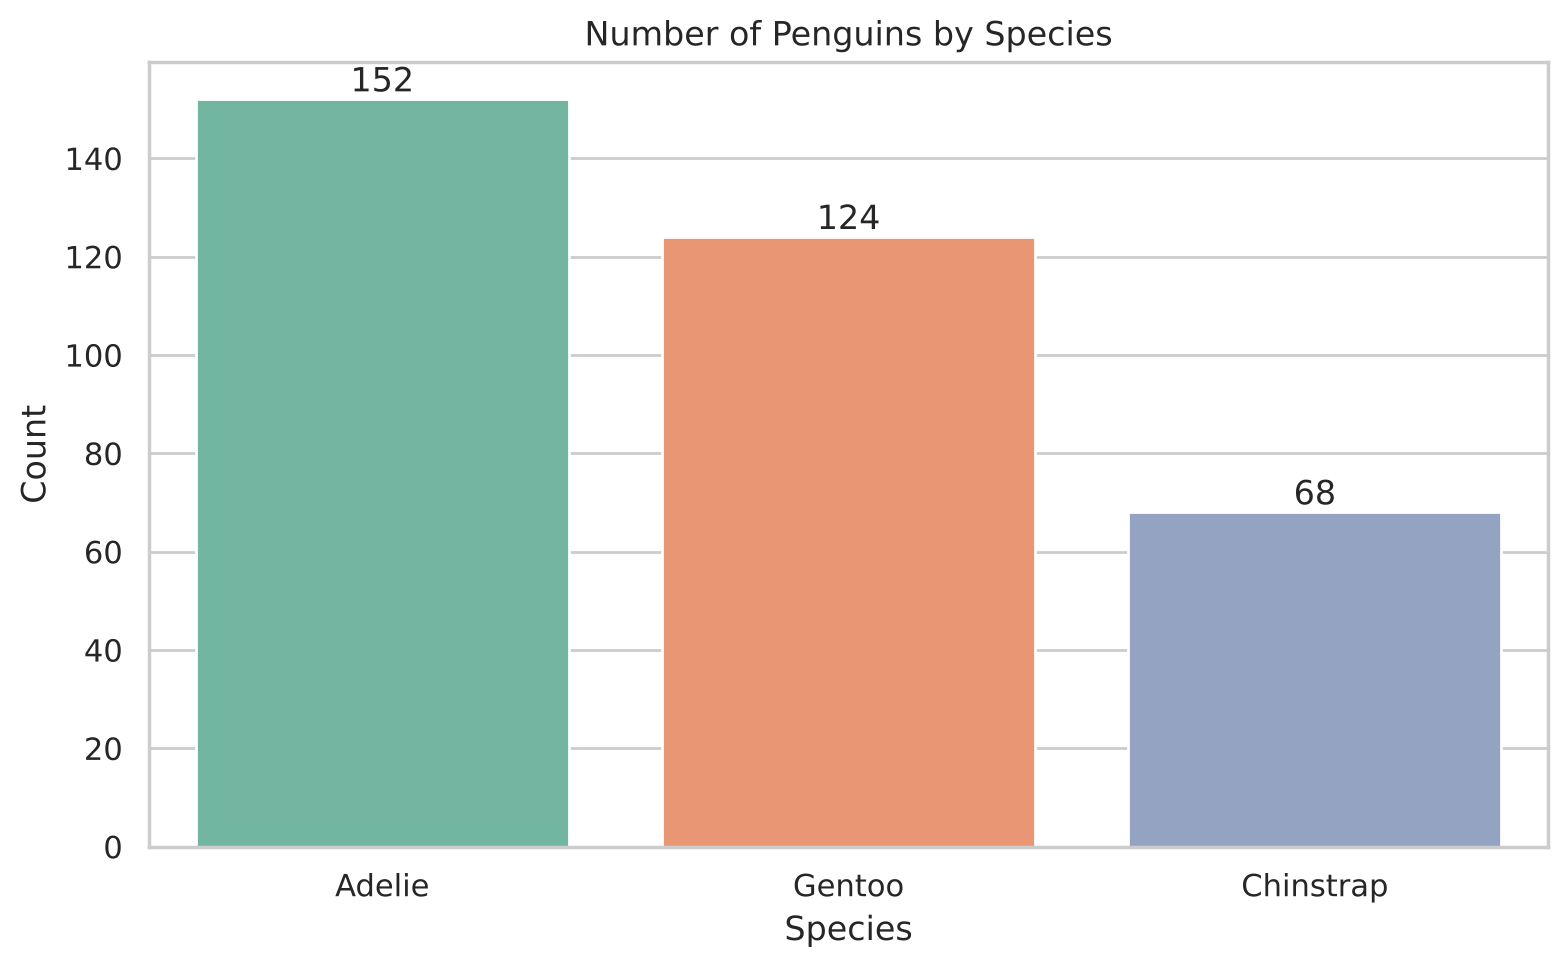

In [15]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='species', order=df['species'].value_counts().index, palette='Set2')
for p in ax.patches: ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.title('Number of Penguins by Species'); plt.xlabel('Species'); plt.ylabel('Count')
plt.tight_layout(); plt.savefig('figures/05_bar_species.png', dpi=150); plt.show()

**Interpretation.** Adelie is the largest group (152), then Gentoo (124) and Chinstrap (68); the classes are imbalanced, which matters if `species` is used as the prediction target later.

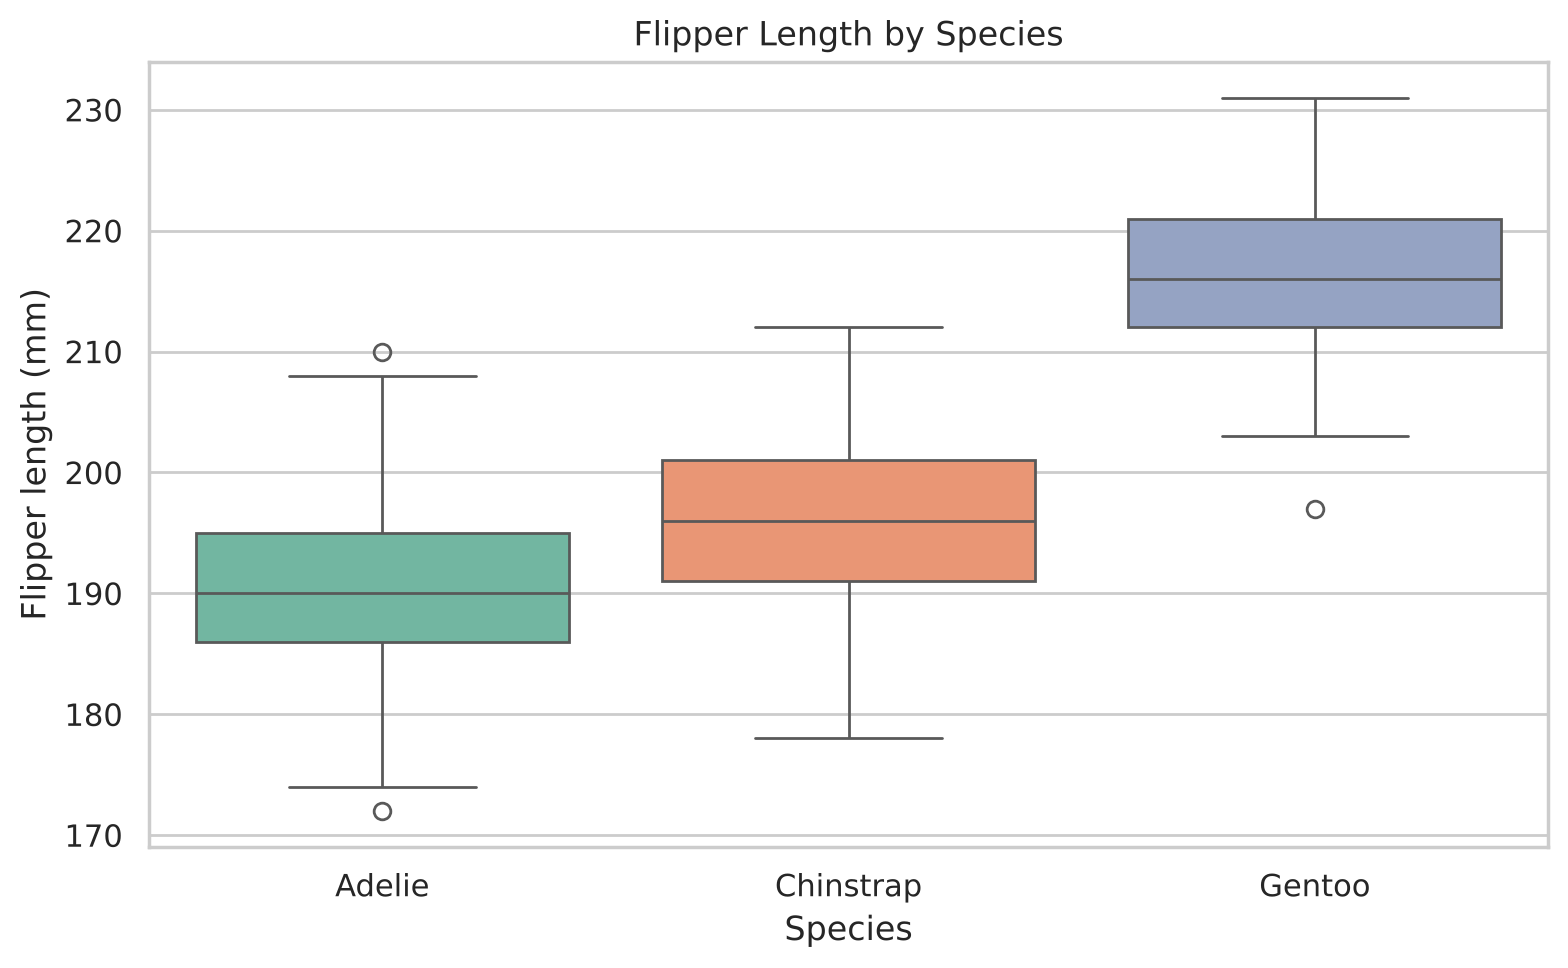

In [16]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='species', y='flipper_length_mm', palette='Set2')
plt.title('Flipper Length by Species'); plt.xlabel('Species'); plt.ylabel('Flipper length (mm)')
plt.tight_layout(); plt.savefig('figures/06_box_flipper_species.png', dpi=150); plt.show()

**Interpretation.** Gentoo penguins have clearly longer flippers (median above 215 mm) than Adelie and Chinstrap (about 190–196 mm), so flipper length separates Gentoo from the others well, and there are no extreme outliers.

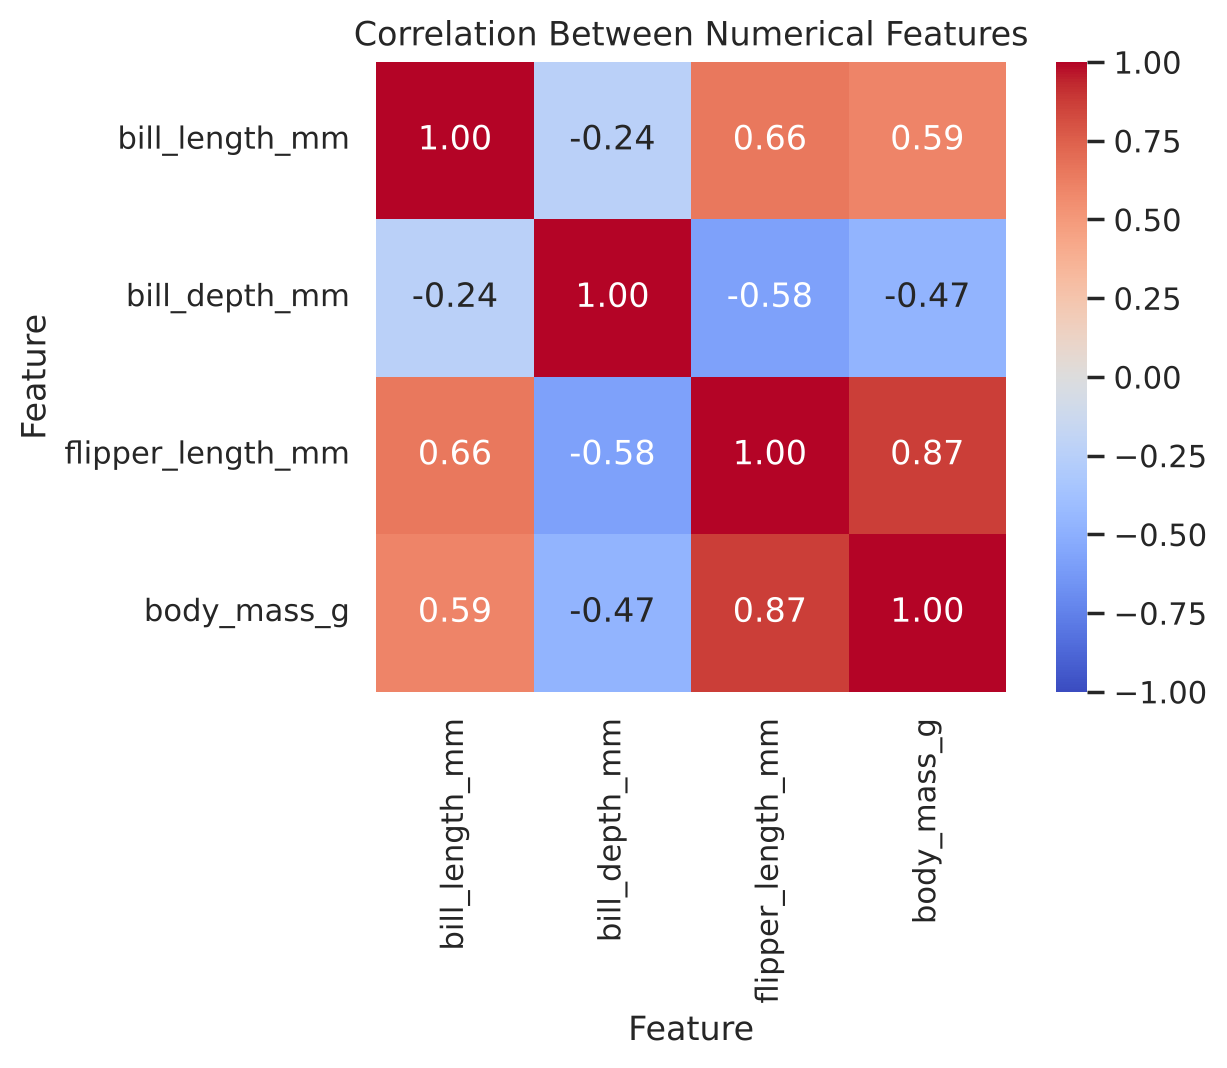

In [17]:
plt.figure(figsize=(7, 5.5))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlation Between Numerical Features'); plt.xlabel('Feature'); plt.ylabel('Feature')
plt.tight_layout(); plt.savefig('figures/07_correlation_heatmap.png', dpi=150); plt.show()

**Interpretation.** Flipper length and body mass are strongly positively correlated (~0.87), and bill length also correlates with both. Bill depth is *negatively* correlated with flipper length and mass overall — a hint of Simpson's paradox, which the next plot checks.

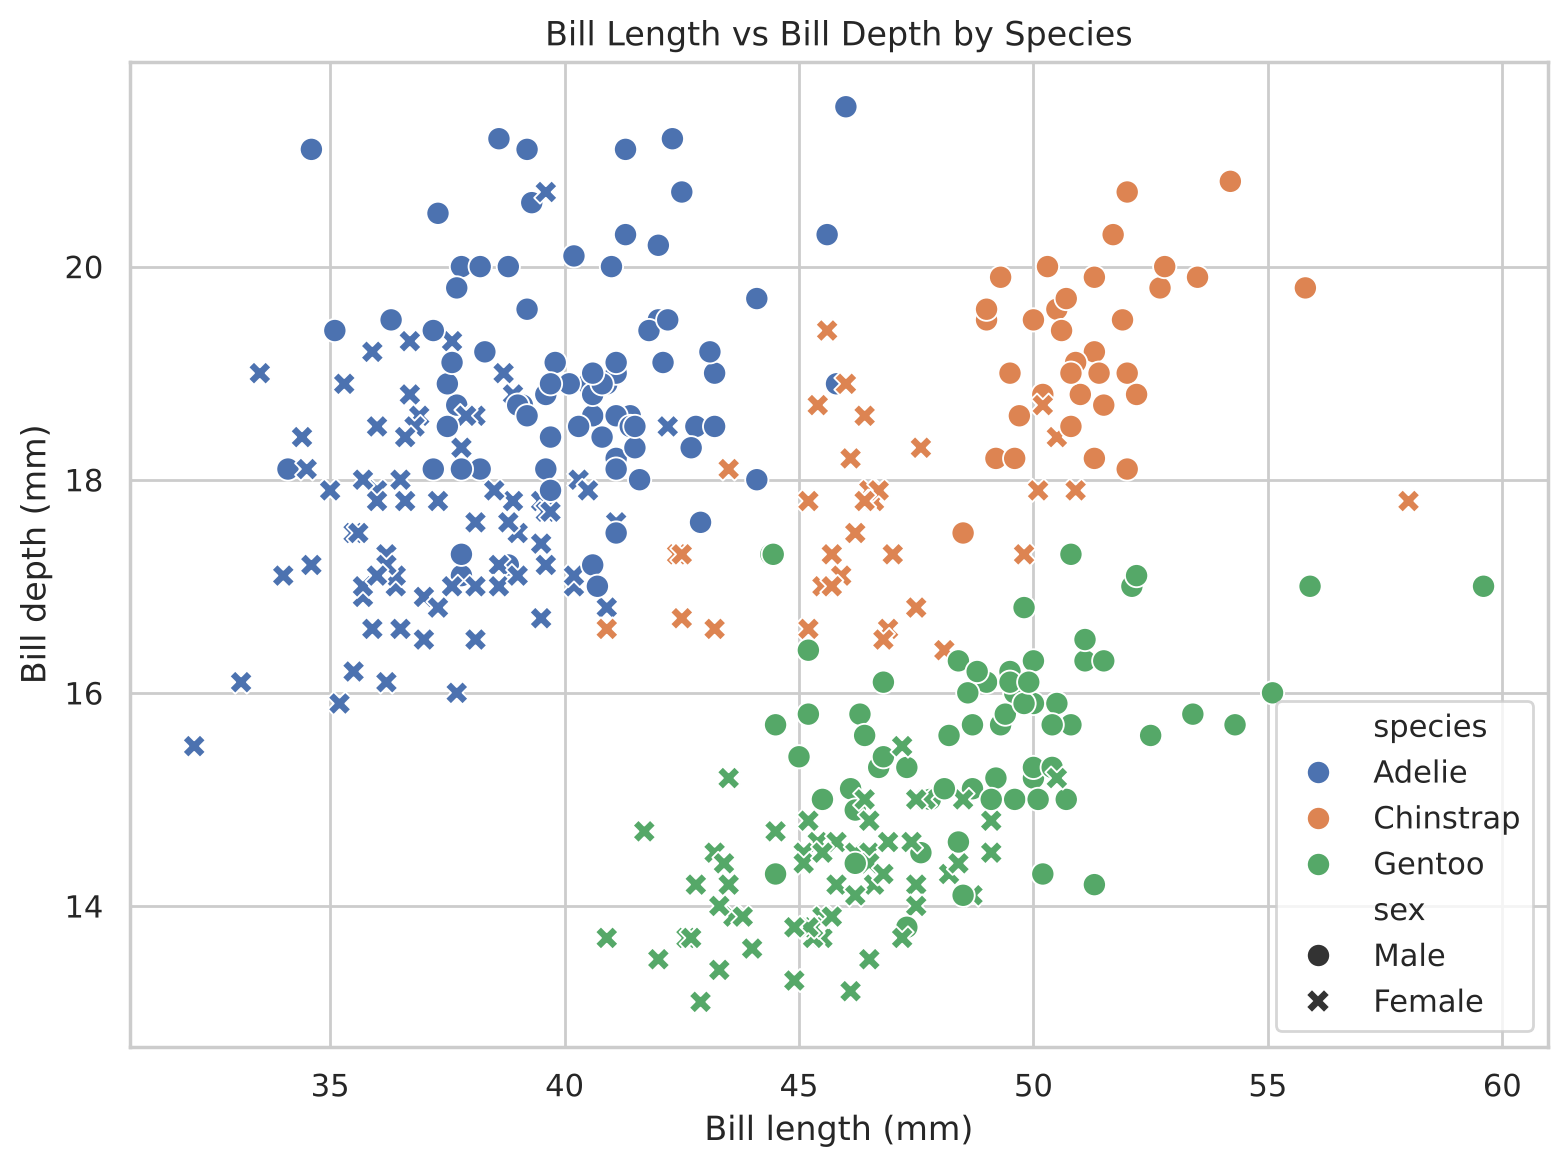

In [18]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='bill_length_mm', y='bill_depth_mm', hue='species', style='sex', s=70)
plt.title('Bill Length vs Bill Depth by Species'); plt.xlabel('Bill length (mm)'); plt.ylabel('Bill depth (mm)')
plt.tight_layout(); plt.savefig('figures/08_scatter_bill.png', dpi=150); plt.show()

**Interpretation (extra).** Overall bill depth falls as bill length rises, but within each species the trend is positive, so the three species form clear clusters. This shows `species` is an important variable and a good candidate target for classification.

## Task 7 — Feature Engineering

In [19]:
df['bill_ratio'] = df['bill_length_mm'] / df['bill_depth_mm']
df['body_mass_kg'] = df['body_mass_g'] / 1000
display(df[['bill_length_mm', 'bill_depth_mm', 'bill_ratio', 'body_mass_g', 'body_mass_kg']].head())
display(df.groupby('species')['bill_ratio'].describe().round(2))

,bill_length_mm,bill_depth_mm,bill_ratio,body_mass_g,body_mass_kg
0,39.10,18.7,2.090909,3750.0,3.75
1,39.50,17.4,2.270115,3800.0,3.80
2,40.30,18.0,2.238889,3250.0,3.25
3,44.45,17.3,2.569364,4050.0,4.05
4,36.70,19.3,1.901554,3450.0,3.45


,count,mean,std,min,25%,50%,75%,max
species,,,,,,,,
Adelie,152.0,2.12,0.16,1.64,2.01,2.14,2.24,2.57
Chinstrap,68.0,2.65,0.15,2.35,2.56,2.66,2.73,3.26
Gentoo,124.0,3.17,0.18,2.57,3.06,3.16,3.28,3.61


**Justification.** `bill_ratio` = bill length ÷ bill depth describes the *shape* of the bill (long and thin vs. short and deep) instead of its size. Size is already captured by mass and flipper length, so this adds new information, and the table shows the ratio differs by species (Gentoo has the highest). Ratios like this often help models separate classes and are less affected by overall body size. `body_mass_kg` is just a unit conversion for readability.

## Task 8 — Encode Categorical Variables

In [20]:
print('Categorical columns:', df.select_dtypes(include='object').columns.tolist())
print('BEFORE encoding:'); display(df[['species', 'island', 'sex']].head())

Categorical columns: ['species', 'island', 'sex']
BEFORE encoding:


,species,island,sex
0,Adelie,Torgersen,Male
1,Adelie,Torgersen,Female
2,Adelie,Torgersen,Female
3,Adelie,Torgersen,Male
4,Adelie,Torgersen,Female


In [21]:
from sklearn.preprocessing import LabelEncoder

# Label Encoding: sex (binary variable: Female=0, Male=1)
le = LabelEncoder()
df['sex_encoded'] = le.fit_transform(df['sex'])
print('Label encoding mapping:', dict(zip(le.classes_, le.transform(le.classes_))))

# One-Hot Encoding: island (nominal, no order, 3 categories)
df = pd.get_dummies(df, columns=['island'], prefix='island', dtype=int)

print('\nAFTER encoding:')
display(df[['species', 'sex', 'sex_encoded'] + [c for c in df.columns if c.startswith('island_')]].head(8))

Label encoding mapping: {'Female': np.int64(0), 'Male': np.int64(1)}

AFTER encoding:


,species,sex,sex_encoded,island_Biscoe,island_Dream,island_Torgersen
0,Adelie,Male,1,0,0,1
1,Adelie,Female,0,0,0,1
2,Adelie,Female,0,0,0,1
3,Adelie,Male,1,0,0,1
4,Adelie,Female,0,0,0,1
5,Adelie,Male,1,0,0,1
6,Adelie,Female,0,0,0,1
7,Adelie,Male,1,0,0,1


**Rationale.** *Label Encoding* is used for `sex` because it has only two values (Female = 0, Male = 1), so one 0/1 column is enough and implies no false ranking. *One-Hot Encoding* is used for `island` because it is nominal with three unrelated values; integer codes 0/1/2 would wrongly imply Torgersen < Dream < Biscoe, so each island gets its own 0/1 column. `species` is left as text because it is the likely target for the next assignment, and I did not want to encode it unnecessarily.

## Task 9 — Feature Scaling

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

scale_cols = ['bill_length_mm', 'flipper_length_mm', 'body_mass_g']
X = df.drop(columns=['species'])                    # species = target, excluded from scaling
y = df['species']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, ' Test:', X_test.shape)

mm, ss = MinMaxScaler(), StandardScaler()
mm_train = mm.fit_transform(X_train[scale_cols]);  mm_test = mm.transform(X_test[scale_cols])   # fit on train only
ss_train = ss.fit_transform(X_train[scale_cols]);  ss_test = ss.transform(X_test[scale_cols])

comparison = pd.DataFrame({
    'body_mass_g (original)': X_train['body_mass_g'].values,
    'body_mass MinMax':       mm_train[:, 2],
    'body_mass Standard':     ss_train[:, 2]}).head(8)
display(comparison.round(3))

stats = pd.DataFrame({
    'original_mean': X_train[scale_cols].mean(), 'original_std': X_train[scale_cols].std(),
    'minmax_min': mm_train.min(axis=0), 'minmax_max': mm_train.max(axis=0),
    'standard_mean': ss_train.mean(axis=0), 'standard_std': ss_train.std(axis=0, ddof=1)}, index=scale_cols)
display(stats.round(3))

Train: (275, 11)  Test: (69, 11)


,body_mass_g (original),body_mass MinMax,body_mass Standard
0,2900.0,0.056,-1.635
1,3900.0,0.333,-0.387
2,3350.0,0.181,-1.073
3,5350.0,0.736,1.422
4,5400.0,0.750,1.485
5,5300.0,0.722,1.360
6,3475.0,0.215,-0.917
7,5350.0,0.736,1.422


,original_mean,original_std,minmax_min,minmax_max,standard_mean,standard_std
bill_length_mm,44.071,5.480,0.0,1.0,-0.0,1.002
flipper_length_mm,200.818,13.917,0.0,1.0,0.0,1.002
body_mass_g,4210.091,802.918,0.0,1.0,0.0,1.002


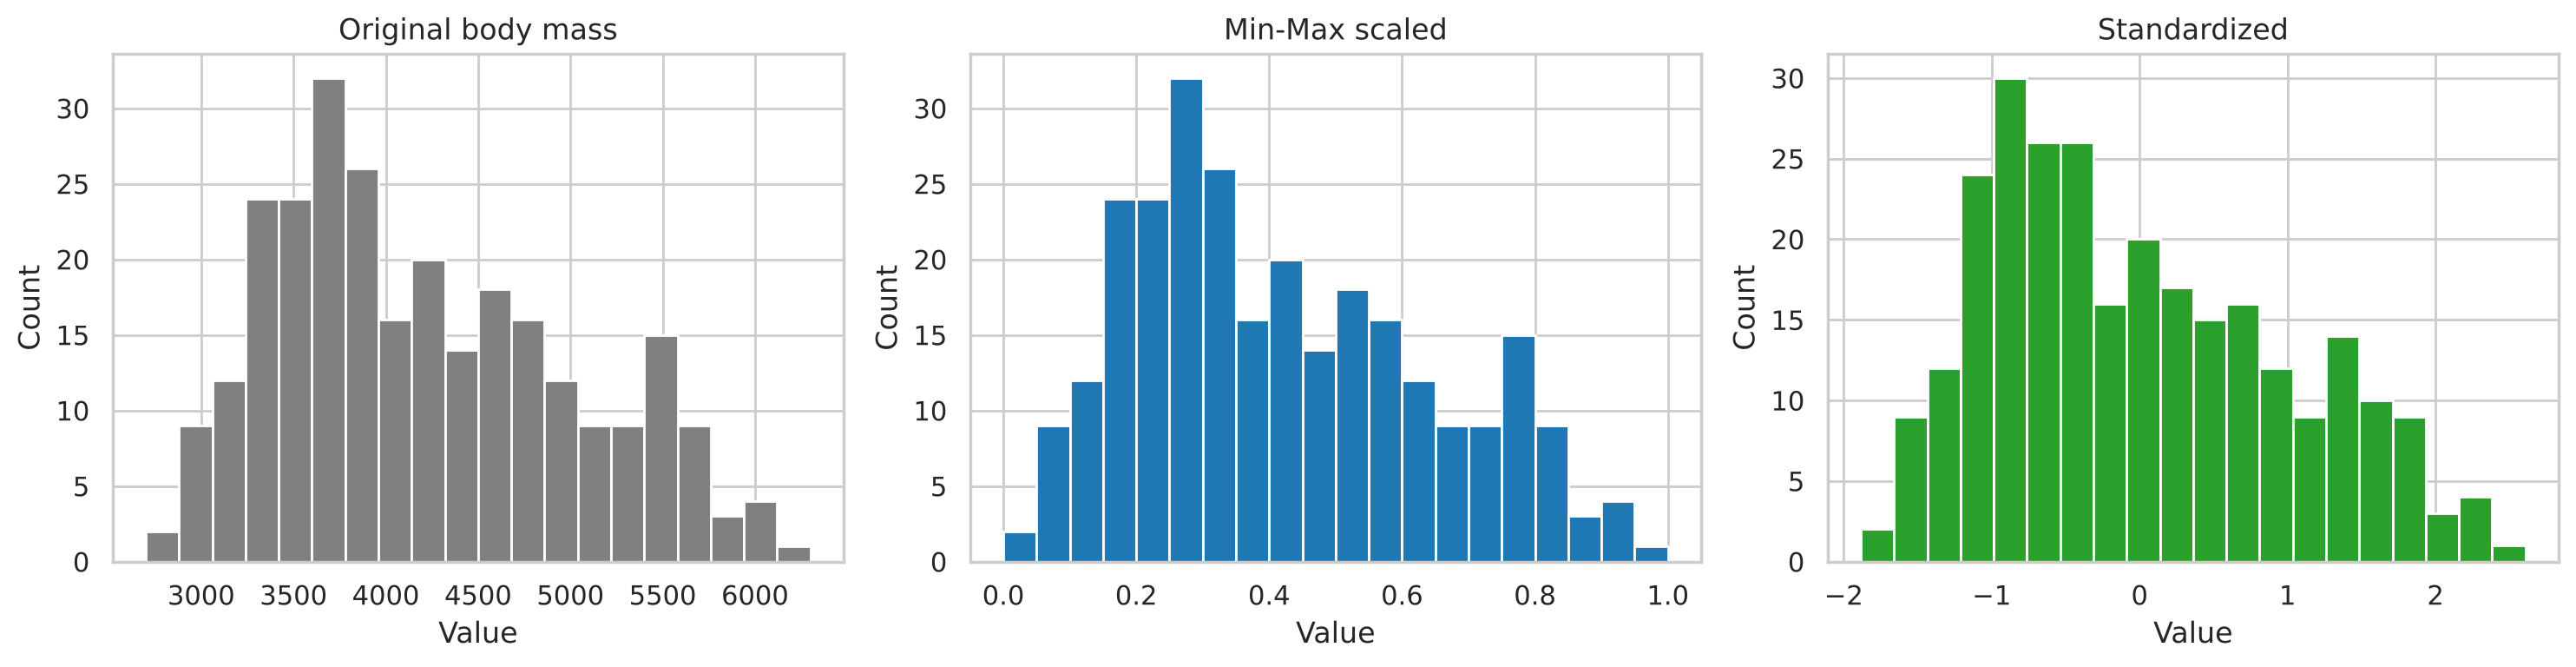

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(X_train['body_mass_g'], bins=20, color='gray');  ax[0].set_title('Original body mass')
ax[1].hist(mm_train[:, 2], bins=20, color='tab:blue');      ax[1].set_title('Min-Max scaled')
ax[2].hist(ss_train[:, 2], bins=20, color='tab:green');     ax[2].set_title('Standardized')
for a in ax: a.set_xlabel('Value'); a.set_ylabel('Count')
plt.tight_layout(); plt.savefig('figures/09_scaling_comparison.png', dpi=150); plt.show()

**Explanation.** **Min-Max scaling** maps each feature to the range [0, 1] using `(x − min)/(max − min)`; the shape of the distribution is unchanged but it is sensitive to outliers because they set the min/max. It suits bounded-input methods such as neural networks and distance-based methods like KNN. **Standardization** uses `(x − mean)/std` so the feature has mean 0 and standard deviation 1 (no fixed range); it is more robust to outliers and the usual choice for SVM, logistic/linear regression, and PCA. Without scaling, `body_mass_g` (thousands) would dominate `bill_length_mm` (tens) in these algorithms. The scalers were **fitted on the training set only** and then applied to the test set to avoid data leakage, and the target `species` was excluded.

## Task 10 — Prepare and Save the Cleaned Dataset

In [24]:
print('Missing values remaining:', int(df.isnull().sum().sum()))
print('Duplicate rows remaining:', int(df.duplicated().sum()))
print('Data types:'); print(df.dtypes)
display(df.head(10))
df.to_csv('penguins_cleaned.csv', index=False)
print('\nSaved penguins_cleaned.csv')
print('Final rows   :', df.shape[0])
print('Final columns:', df.shape[1])
print(pd.read_csv('penguins_cleaned.csv').shape, '<- re-loaded from disk to confirm')

Missing values remaining: 0
Duplicate rows remaining: 0
Data types:
species                  str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
bill_ratio           float64
body_mass_kg         float64
sex_encoded            int64
island_Biscoe          int64
island_Dream           int64
island_Torgersen       int64
dtype: object


,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,bill_ratio,body_mass_kg,sex_encoded,island_Biscoe,island_Dream,island_Torgersen
0,Adelie,39.10,18.7,181.0,3750.0,Male,2.090909,3.750,1,0,0,1
1,Adelie,39.50,17.4,186.0,3800.0,Female,2.270115,3.800,0,0,0,1
2,Adelie,40.30,18.0,195.0,3250.0,Female,2.238889,3.250,0,0,0,1
3,Adelie,44.45,17.3,197.0,4050.0,Male,2.569364,4.050,1,0,0,1
4,Adelie,36.70,19.3,193.0,3450.0,Female,1.901554,3.450,0,0,0,1
5,Adelie,39.30,20.6,190.0,3650.0,Male,1.907767,3.650,1,0,0,1
6,Adelie,38.90,17.8,181.0,3625.0,Female,2.185393,3.625,0,0,0,1
7,Adelie,39.20,19.6,195.0,4675.0,Male,2.000000,4.675,1,0,0,1
8,Adelie,34.10,18.1,193.0,3475.0,Male,1.883978,3.475,1,0,0,1
9,Adelie,42.00,20.2,190.0,4250.0,Male,2.079208,4.250,1,0,0,1



Saved penguins_cleaned.csv
Final rows   : 344
Final columns: 12
(344, 12) <- re-loaded from disk to confirm


**Summary.** All checks pass: no missing values, no duplicates, consistent text formatting, outliers examined (all retained), a new feature added, `sex` label-encoded and `island` one-hot encoded. The saved CSV (`penguins_cleaned.csv`) keeps the **unscaled** values so that scaling can be fitted correctly on the training split in the next assignment (scaling was demonstrated in Task 9 without overwriting the data).

## Conclusion (major findings and preprocessing decisions)
- The dataset contains 344 penguins of three species with four body measurements. Missing data was small (19 cells, 0.8%): 2 rows without measurements and 11 without `sex`. I filled numerics with the **median** and `sex` with the **mode** to keep all rows.
- There were **no duplicates** and no spelling inconsistencies; only the capitalisation of `sex` was standardised.
- IQR analysis found **no outliers** in the four numeric columns, so nothing was removed; all values are plausible biological variation.
- Flipper length, body mass and bill length are strongly related, and the species form distinct clusters (Gentoo is the biggest), so the data should be well suited to classification.
- I engineered `bill_ratio`, encoded `sex` (label) and `island` (one-hot), and showed Min-Max and Standard scaling with a leak-free train/test split.
- Final dataset: see the output of Task 10 for exact rows and columns.

## Section 6 — Additional Questions

**1. Why is data preprocessing important before training an AI model?**
Models learn only from the data they are given. Raw data contains missing values, errors, inconsistent formats and features on different scales, and most algorithms cannot handle these. Preprocessing turns the data into a clean numerical form so the model learns real patterns, not noise.

**2. What is the difference between missing values and duplicate records?**
Missing values are empty cells (information that was not recorded), so a row is incomplete. Duplicate records are rows repeated more than once, so the same observation is counted twice. Missing values are filled or removed, while duplicates are deleted so the data isn't double-counted.

**3. Why is the median sometimes preferred over the mean when handling missing values?**
The mean is pulled by extreme values and skewed distributions, while the median is the middle value and is not affected by outliers. In skewed data the median is a more typical fill value and doesn't distort the distribution.

**4. What are outliers, and why should we not automatically remove them?**
Outliers are values far from the rest of the data. They may be errors (typos, sensor faults) but can also be real, rare cases (e.g. a very heavy penguin). Removing real ones throws away information and bias the model, so we investigate first and remove only those that are errors.

**5. What is the difference between Label Encoding and One-Hot Encoding?**
Label Encoding replaces each category with an integer in one column (e.g. Female=0, Male=1), which implies an order, so it fits binary or ordinal variables. One-Hot Encoding creates a separate 0/1 column per category with no implied order, which fits nominal variables such as island, at the cost of more columns.

**6. Why is feature scaling important for some machine learning algorithms?**
Algorithms based on distances or gradients (KNN, SVM, neural networks, linear/logistic regression, PCA) are dominated by features with large numeric ranges. Scaling puts features on a comparable range so each contributes fairly and training converges faster. Tree-based models don't need it.

**7. What problems could occur if we train a machine learning model on uncleaned data?**
Poor accuracy and a biased or unreliable model, because noise, errors and wrong values mislead it; crashes or errors from NaN values and text columns; overfitting or inflated metrics from duplicates; and misleading results because some features dominate due to scale. Garbage in, garbage out.